# Franka in Isaac Lab: VLM grounding + scripted grasping
### Where do pick failures come from (the VLM, perception, the grasp, or the controller), and how does VLM size matter?

**Setup in one line.** A Franka Panda with the standard Franka Hand stands at a table with 6 random YCB objects. An external RGB-D camera (RealSense D435 intrinsics) and a wrist RGB-D camera observe the scene. The instruction is *"pick up the ⟨object⟩"*. The pipeline:
1. depth clustering proposes candidate objects;
2. a local VLM picks which candidate is the target;
3. a scripted top-down grasp is planned from the object's points;
4. our numpy IK turns each move into a joint trajectory, which the robot executes.

**Built to move to the real arm.** Everything above the `Robot` interface (perception, VLM, grasp planner, IK, episode logic) is shared between the Isaac backend and the real-robot backend (franky + RealSense, `vrg/franka/real_franky.py`). The simulator only adds an *oracle*: ground-truth masks and object poses, used to score episodes and to attribute failures, never by the method.

**Protocol.**
* Scenes are seeds; every graspable object in a scene is the target once.
* **Dev** = seeds 0–9 (used to debug and to pick each VLM's grounding mode).
* **Eval** = seeds 100–149, 257 episodes per configuration, untouched during development.
* Brackets are Wilson 95% CIs.

In [1]:
import json, os, glob, math, collections
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Video, Image
ROOT = os.path.abspath('..'); RUNS = f'{ROOT}/runs/franka'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
                     'axes.axisbelow': True, 'figure.facecolor': 'white', 'legend.frameon': False})
def load(name):
    p = f'{RUNS}/{name}/results.json'; return json.load(open(p)) if os.path.exists(p) else []
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z*z/n; c = (p + z*z/(2*n)) / d; h = z*math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d; return c - h, c + h
def rate(R, key='success'):
    k, n = sum(bool(r.get(key)) for r in R), len(R); lo, hi = wilson(k, n); return dict(sr=k/n if n else np.nan, lo=lo, hi=hi, n=n, k=k)
def fmt(R, key='success'):
    s = rate(R, key); return 'pending' if s['n'] == 0 else f"{100*s['sr']:.1f}% [{100*s['lo']:.0f}–{100*s['hi']:.0f}] (n={s['n']})"
def table(rows, header):
    out = '| ' + ' | '.join(header) + ' |\n|' + '---|' * len(header) + '\n'
    for r in rows: out += '| ' + ' | '.join(str(x) for x in r) + ' |\n'
    display(Markdown(out))
def show(path, w=640, caption=None):
    if os.path.exists(path):
        if caption: display(Markdown(caption))
        display(Video(path, embed=True, width=w, html_attributes='controls loop muted'))
FAILS = ['segmentation', 'grounding', 'grasp_plan', 'ik', 'ik_lift', 'approach_collision', 'reach', 'grasp_miss', 'grasp_slip', 'wrong_object']
FC = {'success': '#2a78d6', 'segmentation': '#8a8984', 'grounding': '#eb6834', 'grasp_plan': '#c3c2b7', 'ik': '#52514e', 'ik_lift': '#3a3936',
      'approach_collision': '#eda100', 'reach': '#b8860b', 'grasp_miss': '#1baf7a', 'grasp_slip': '#0e7a55', 'wrong_object': '#a83232', 'other': '#dddddd'}
print('runs:', sorted(os.listdir(RUNS)) if os.path.isdir(RUNS) else 'none')

runs: ['e1_a_extonly', 'e1_b_refine', 'e1_c_fixedyaw', 'e1_d_joint', 'e1_e_native', 'e1_f_gtseg', 'e3_qwen3vl-2b', 'e3_qwen3vl-32b', 'e3_qwen3vl-4b', 'e3_qwen3vl-8b', 'ground_eval']


---
## 1. Setup: a simulator that mirrors the real cell

| | Simulation (Isaac Lab 2.3 / Isaac Sim 5.1) | Real robot (planned) |
|---|---|---|
| Arm, gripper | Franka Panda, Franka Hand (Isaac Lab asset), PD joint control, gravity-compensated | Franka via FCI with **franky** (libfranka), Franka Hand |
| External camera | RGB-D 640×480, fx = fy = 615 px (D435 colour intrinsics), on a "tripod" opposite the robot | RealSense D435/D455; extrinsics from calibration (`calib.json`) |
| Wrist camera | RGB-D on the hand, 6.5 cm off-axis, parallel to the fingers | RealSense on the hand; hand-eye calibration |
| Objects | 6 random YCB objects per scene, dropped and settled at random yaw | the physical YCB set (same objects) |
| Motion | joint trajectories from our IK, sent as joint position targets at 100 Hz | the same trajectories, as franky joint waypoints |

**Code map** (`vrg/franka/`):
* `core.py`: interface and types;
* `kinematics.py`: Panda forward kinematics, Jacobian, damped-least-squares IK, joint and Cartesian planners;
* `perception.py`: table fit, object proposals, top-down grasp;
* `vlm.py`: the three grounding modes;
* `episode.py`: the backend-agnostic episode loop;
* `isaac_backend.py` and `real_franky.py`: the two backends;
* `run_isaac.py` and `ground_offline.py`: experiment drivers.

**Sanity checks.**
* The numpy kinematics match Isaac's TCP to 0.0 mm and 0.0 rad at the home pose.
* IK solves 200/200 random reachable poses in about 1 ms each.
* The joint-trajectory tracking error at the end of a move is about 2–4 mm.

**Engineering note.** CPU PhysX is about 36× faster than GPU PhysX for one robot and a few objects (0.5 vs 18 ms per step); rendering stays on the GPU.

A random evaluation scene from the external camera:

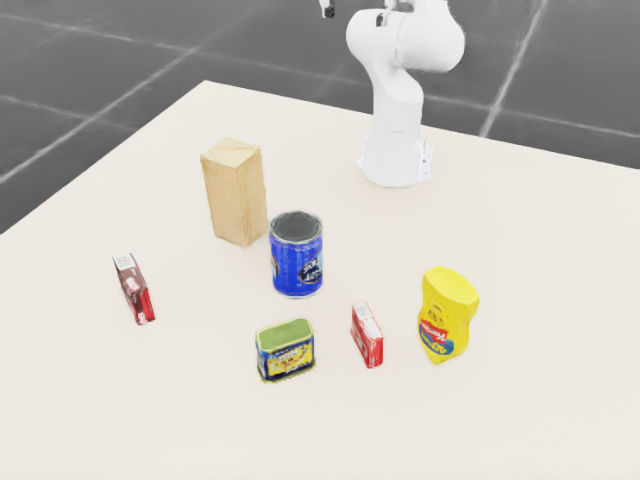

In [2]:
p = f'{ROOT}/demo/franka/scene.png'
if os.path.exists(p): display(Markdown('A random evaluation scene from the external camera:')); display(Image(p, width=560))

### The pipeline and how a failure is attributed

Each episode records the outcome of every stage, and the **first** broken stage is its failure label:

| Stage | Failure label | Meaning |
|---|---|---|
| perception | `segmentation` | no depth proposal is (mostly) the target object |
| grounding (VLM) | `grounding` | the chosen proposal is a different object |
| grasp planning | `grasp_plan` | the object is wider than the 8 cm Franka Hand from above |
| IK | `ik`, `ik_lift` | no joint solution for the pre-grasp, approach or lift |
| approach | `approach_collision` | the fingers hit the target or a neighbour before closing (TCP stopped > 1 cm short and something moved) |
| controller | `reach` | the TCP ended > 1 cm from the goal with nothing disturbed (tracking error) |
| grasp | `grasp_miss` / `grasp_slip` / `wrong_object` | closed on nothing / held but dropped when lifting / lifted something else |

Success means the target ended up more than 5 cm above where it started.

---
## 2. The grasp and the controller, with a perfect VLM

To separate the robot side from the VLM, these runs use **oracle grounding**: the proposal that ground truth says is the target. Perception is still the real depth-clustering pipeline (except in config f).

| Config | Perception | Grasp | Controller |
|---|---|---|---|
| a | external camera only | top-down, angle from footprint PCA | joint move to pre-grasp, straight-line approach and lift (our IK) |
| b | **+ wrist "look" before grasping** | same | same |
| c | + look | **fixed angle** (no PCA) | same |
| d | + look | PCA | **joint-space** moves only (curved TCP path) |
| e | + look | PCA | **Isaac's DifferentialIK (DLS)** tracking the goal pose directly |
| f | + look, **ground-truth segmentation** | PCA | straight-line |

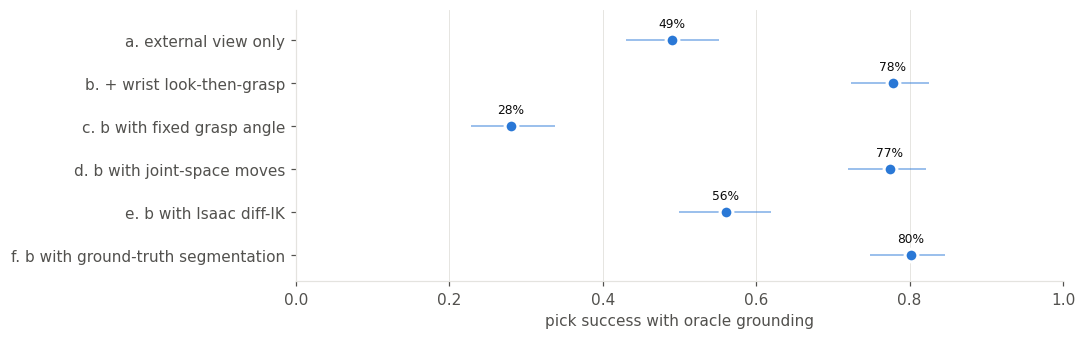

| Config | Success | median TCP error at grasp pose | wall time / episode |
|---|---|---|---|
| a. external view only | 49.0% [43–55] (n=257) | 4.1 mm | 2.0 s |
| b. + wrist look-then-grasp | 77.8% [72–82] (n=257) | 3.4 mm | 3.0 s |
| c. b with fixed grasp angle | 28.0% [23–34] (n=257) | 3.5 mm | 1.7 s |
| d. b with joint-space moves | 77.4% [72–82] (n=257) | 3.6 mm | 2.1 s |
| e. b with Isaac diff-IK | 56.0% [50–62] (n=257) | 2.9 mm | 2.2 s |
| f. b with ground-truth segmentation | 80.2% [75–85] (n=257) | 3.4 mm | 2.3 s |


In [3]:
E1 = [('a. external view only', 'e1_a_extonly'), ('b. + wrist look-then-grasp', 'e1_b_refine'), ('c. b with fixed grasp angle', 'e1_c_fixedyaw'),
      ('d. b with joint-space moves', 'e1_d_joint'), ('e. b with Isaac diff-IK', 'e1_e_native'), ('f. b with ground-truth segmentation', 'e1_f_gtseg')]
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, (lab, run) in enumerate(E1[::-1]):
    r = rate(load(run))
    if not r['n']: ax.text(0.01, i, 'pending', va='center', fontsize=8, color=INK2); continue
    ax.errorbar(r['sr'], i, xerr=[[r['sr'] - r['lo']], [r['hi'] - r['sr']]], fmt='none', ecolor='#2a78d6', elinewidth=1, alpha=0.6)
    ax.scatter(r['sr'], i, s=70, color='#2a78d6', edgecolors='white', linewidths=2, zorder=3)
    ax.text(r['sr'], i + 0.3, f"{100*r['sr']:.0f}%", ha='center', fontsize=8, color=INK)
ax.set_yticks(range(len(E1))); ax.set_yticklabels([l for l, _ in E1[::-1]]); ax.set_xlim(0, 1); ax.set_ylim(-0.6, len(E1) - 0.3)
ax.set_xlabel('pick success with oracle grounding'); ax.grid(axis='y', visible=False); plt.show()
table([[l, fmt(load(r)), f"{np.nanmedian([x.get('reach_err', np.nan) for x in load(r)])*1000:.1f} mm" if load(r) else '–',
        f"{np.mean([x['sec'] for x in load(r)]):.1f} s" if load(r) else '–'] for l, r in E1],
      ['Config', 'Success', 'median TCP error at grasp pose', 'wall time / episode'])

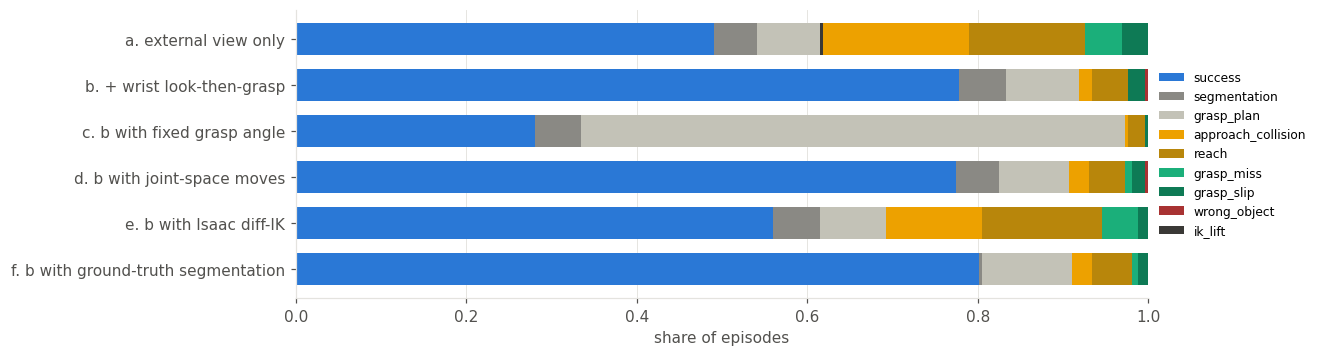

| Config | segmentation | grounding | grasp_plan | ik | ik_lift | approach_collision | reach | grasp_miss | grasp_slip | wrong_object |
|---|---|---|---|---|---|---|---|---|---|---|
| a. external view only | 13 | 0 | 19 | 0 | 1 | 44 | 35 | 11 | 8 | 0 |
| b. + wrist look-then-grasp | 14 | 0 | 22 | 0 | 0 | 4 | 11 | 0 | 5 | 1 |
| c. b with fixed grasp angle | 14 | 0 | 164 | 0 | 0 | 1 | 5 | 0 | 1 | 0 |
| d. b with joint-space moves | 13 | 0 | 21 | 0 | 0 | 6 | 11 | 2 | 4 | 1 |
| e. b with Isaac diff-IK | 14 | 0 | 20 | 0 | 0 | 29 | 36 | 11 | 3 | 0 |
| f. b with ground-truth segmentation | 1 | 0 | 27 | 0 | 0 | 6 | 12 | 2 | 3 | 0 |


In [4]:
# First broken stage, per config
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (lab, run) in enumerate(E1[::-1]):
    R = load(run)
    if not R: continue
    c = collections.Counter('success' if x.get('success') else (x['fail'] if x['fail'] in FC else 'other') for x in R); left = 0
    for k in ['success'] + FAILS + ['other']:
        v = c.get(k, 0) / len(R)
        if v: ax.barh(i, v, left=left, color=FC[k], height=0.7, label=k if k not in ax.get_legend_handles_labels()[1] else None); left += v
ax.set_yticks(range(len(E1))); ax.set_yticklabels([l for l, _ in E1[::-1]]); ax.set_xlim(0, 1); ax.grid(axis='y', visible=False)
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8); ax.set_xlabel('share of episodes'); plt.show()
table([[l] + [collections.Counter(x['fail'] for x in load(r) if not x.get('success')).get(k, 0) for k in FAILS] for l, r in E1 if load(r)], ['Config'] + FAILS)

In [5]:
# Per object (config b): which objects are hard for a top-down scripted grasp?
R = load('e1_b_refine')
if R:
    by = collections.defaultdict(list)
    for x in R: by[x['target']].append(x)
    rows = sorted(by.items(), key=lambda kv: -np.mean([bool(x.get('success')) for x in kv[1]]))
    table([[k, f"{sum(bool(x.get('success')) for x in v)}/{len(v)}", ', '.join(f'{a} {b}' for a, b in collections.Counter(x['fail'] for x in v if not x.get('success')).most_common(3))]
           for k, v in rows], ['Object', 'Success (config b)', 'Main failures'])

| Object | Success (config b) | Main failures |
|---|---|---|
| pudding box | 13/13 |  |
| bleach bottle | 25/27 | grasp_plan 1, segmentation 1 |
| foam brick | 19/21 | approach_collision 1, segmentation 1 |
| sugar box | 18/20 | reach 1, segmentation 1 |
| tomato soup can | 18/20 | reach 2 |
| mustard bottle | 15/18 | reach 2, grasp_plan 1 |
| marker | 15/18 | reach 2, segmentation 1 |
| potted meat can | 18/22 | grasp_plan 2, approach_collision 1, grasp_slip 1 |
| banana | 17/22 | grasp_plan 3, approach_collision 1, segmentation 1 |
| gelatin box | 16/22 | reach 3, segmentation 2, wrong_object 1 |
| clamp | 11/19 | grasp_slip 4, segmentation 2, grasp_plan 1 |
| cracker box | 9/19 | grasp_plan 10 |
| scissors | 6/16 | segmentation 5, grasp_plan 4, approach_collision 1 |


**Reading section 2.**
* **The wrist look matters most: 49% → 78%.** The external camera sees objects from about 1.1 m at 640×480, so its point clouds are partial (one side only) and its grasp centres and angles are off by up to a few cm. That shows up as `approach_collision` (44: the fingers come down on the object) and `reach` (35). One extra stop 22 cm above the object to re-segment it from the wrist camera removes most of both.
* **The grasp angle has to come from the object: fixed angle 28%.** With PCA the gripper closes across the narrow side. With a fixed angle, most objects are wider than the planner's 7.5 cm opening limit along that direction, and the planner refuses (`grasp_plan` 164).
* **Our IK beats Isaac's differential IK (78% vs 56%) on the same targets.** Isaac's `DifferentialIKController` (one damped least-squares step per control tick, toward the final goal) often stalls 4–5 cm short with the hand tilted when the goal asks for a large wrist rotation (see the `e1_e_native` videos). Our controller plans first:
  * IK at the goal with joint limits, a null-space posture term and random restarts;
  * then a minimum-jerk joint path to the pre-grasp pose, and a straight Cartesian line (IK per waypoint) for the approach and lift.

  When both controllers converge, they are equally precise (median TCP error about 3 mm in the table). The difference is the tail: diff-IK ends more than 1 cm off, or hits the object on the way, in 65 episodes (`reach` 36 + `approach_collision` 29), against 15 for ours. Joint-space moves for every segment do as well (77%), so in sim the straight-line approach doesn't buy much. It should matter more on the real arm next to other objects.
* **Perception is a small part of the gap: ground-truth segmentation adds 2 points (80%).** What's left is mostly the grasp itself, as a top-down parallel-jaw grasp:
  * the **cracker box** (10/19 `grasp_plan`) lies flat and is wider than the hand in every direction from above;
  * the **scissors** and **clamp** are thin or segment poorly, and the clamp slips;
  * everything compact (cans, small boxes, bottles, foam brick) succeeds 85–100% of the time.

  Side grasps for wide objects would be the next robot-side gain.

---
## 3. VLM size: does a bigger model ground better?

Qwen3-VL **2B, 4B, 8B and 32B** (same family, all local) see exactly the same saved evaluation observations: 257 episodes from config b. Each model answers in three modes:
* **point**: "Point to the X" on the full external image; the proposal under (or nearest) the point wins.
* **marks**: proposals are numbered on the image (set-of-marks), and the model answers with a number.
* **verify**: each proposal is cropped and zoomed, and the model's Yes/No logit for "is this the X?" ranks them.

Accuracy is the share of episodes where the chosen proposal is the target. *Given segmented* conditions on the target having a proposal at all, which isolates the VLM from perception.

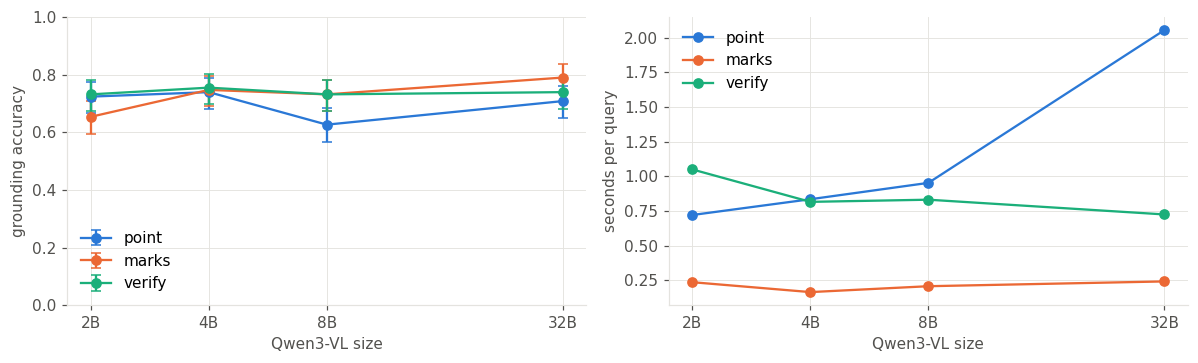

| Model | Mode | Accuracy | Accuracy given segmented | Latency |
|---|---|---|---|---|
| qwen3vl-2b | point | 72.4% [67–77] (n=257) | 78.5% [73–83] (n=237) | 0.72 s |
| qwen3vl-2b | marks | 65.4% [59–71] (n=257) | 70.9% [65–76] (n=237) | 0.24 s |
| qwen3vl-2b | verify | 73.2% [67–78] (n=257) | 79.3% [74–84] (n=237) | 1.05 s |
| qwen3vl-4b | point | 73.9% [68–79] (n=257) | 80.2% [75–85] (n=237) | 0.83 s |
| qwen3vl-4b | marks | 74.7% [69–80] (n=257) | 81.0% [76–85] (n=237) | 0.16 s |
| qwen3vl-4b | verify | 75.5% [70–80] (n=257) | 81.9% [76–86] (n=237) | 0.82 s |
| qwen3vl-8b | point | 62.6% [57–68] (n=257) | 67.9% [62–74] (n=237) | 0.95 s |
| qwen3vl-8b | marks | 73.2% [67–78] (n=257) | 79.3% [74–84] (n=237) | 0.21 s |
| qwen3vl-8b | verify | 73.2% [67–78] (n=257) | 79.3% [74–84] (n=237) | 0.83 s |
| qwen3vl-32b | point | 70.8% [65–76] (n=257) | 76.8% [71–82] (n=237) | 2.06 s |
| qwen3vl-32b | marks | 79.0% [74–84] (n=257) | 85.7% [81–90] (n=237) | 0.24 s |
| qwen3vl-32b | verify | 73.9% [68–79] (n=257) | 80.2% [75–85] (n=237) | 0.72 s |


In [6]:
G = {}
for f in glob.glob(f'{RUNS}/ground_eval/qwen3vl-*_*.json'):
    m, mode = os.path.basename(f)[:-5].rsplit('_', 1); G[(m, mode)] = json.load(open(f))
MODELS = [m for m in ['qwen3vl-2b', 'qwen3vl-4b', 'qwen3vl-8b', 'qwen3vl-32b'] if any(k[0] == m for k in G)]
SIZE = {'qwen3vl-2b': 2, 'qwen3vl-4b': 4, 'qwen3vl-8b': 8, 'qwen3vl-32b': 32}
MC = {'point': '#2a78d6', 'marks': '#eb6834', 'verify': '#1baf7a'}
if G:
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
    for mode, col in MC.items():
        xs, ys, lo, hi, ts = [], [], [], [], []
        for m in MODELS:
            R = list(G.get((m, mode), {}).values())
            if not R: continue
            k = sum(r['correct'] for r in R); a, b = wilson(k, len(R)); xs.append(SIZE[m]); ys.append(k / len(R)); lo.append(a); hi.append(b)
            ts.append(np.mean([r['sec'] for r in R]))
        if not xs: continue
        ys, lo, hi = map(np.array, (ys, lo, hi))
        axs[0].errorbar(xs, ys, yerr=[ys - lo, hi - ys], color=col, marker='o', capsize=3, label=mode)
        axs[1].plot(xs, ts, color=col, marker='o', label=mode)
    for ax in axs: ax.set_xscale('log', base=2); ax.set_xticks([2, 4, 8, 32]); ax.set_xticklabels(['2B', '4B', '8B', '32B']); ax.set_xlabel('Qwen3-VL size')
    axs[0].set_ylabel('grounding accuracy'); axs[0].set_ylim(0, 1); axs[0].legend(); axs[1].set_ylabel('seconds per query'); axs[1].legend()
    plt.tight_layout(); plt.show()
    table([[m, mode, fmt([{'success': r['correct']} for r in G[(m, mode)].values()]),
            fmt([{'success': r['correct']} for r in G[(m, mode)].values() if r['segmented']]), f"{np.mean([r['sec'] for r in G[(m, mode)].values()]):.2f} s"]
           for m in MODELS for mode in MC if (m, mode) in G], ['Model', 'Mode', 'Accuracy', 'Accuracy given segmented', 'Latency'])

In [7]:
# Which objects does the VLM confuse? (best mode per model, chosen on dev scenes)
BEST = json.load(open(f'{RUNS}/ground_eval/best_mode_dev.json')) if os.path.exists(f'{RUNS}/ground_eval/best_mode_dev.json') else {}
for m in MODELS:
    mode = BEST.get(m)
    if (m, mode) not in G: continue
    c = collections.Counter((k.split('|')[1], r['chosen_obj']) for k, r in G[(m, mode)].items() if not r['correct'])
    display(Markdown(f"**{m} ({mode})**, most common confusions (target → chosen): " + '; '.join(f'{a[4:]} → {str(b)[4:] if b else "nothing"} ×{n}' for (a, b), n in c.most_common(6))))

**qwen3vl-2b (point)**, most common confusions (target → chosen): gelatin_box → potted_meat_can ×7; foam_brick → wood_block ×6; sugar_box → gelatin_box ×4; potted_meat_can → tomato_soup_can ×4; sugar_box → pudding_box ×4; potted_meat_can → master_chef_can ×3

**qwen3vl-4b (point)**, most common confusions (target → chosen): foam_brick → wood_block ×6; potted_meat_can → nothing ×5; gelatin_box → pudding_box ×4; bleach_cleanser → nothing ×3; mustard_bottle → nothing ×3; gelatin_box → sugar_box ×3

**qwen3vl-8b (verify)**, most common confusions (target → chosen): foam_brick → gelatin_box ×5; foam_brick → wood_block ×4; potted_meat_can → tomato_soup_can ×3; bleach_cleanser → sugar_box ×3; gelatin_box → pudding_box ×3; banana → nothing ×2

**qwen3vl-32b (marks)**, most common confusions (target → chosen): foam_brick → wood_block ×4; potted_meat_can → tomato_soup_can ×4; gelatin_box → foam_brick ×4; potted_meat_can → master_chef_can ×4; banana → nothing ×3; gelatin_box → pudding_box ×3

---
## 4. Closed loop: who fails, the VLM or the grasp?

Full episodes with each model's VLM choices, using each model's best grounding mode as chosen **on the dev scenes**, with config b's perception, grasp and controller. Every failure is attributed to the first broken stage:
* the **VLM** (wrong object),
* **perception** (the target was never segmented),
* or the **robot side** (grasp plan, IK, approach collision, tracking, grasp miss or slip).

Oracle grounding is the upper bound.

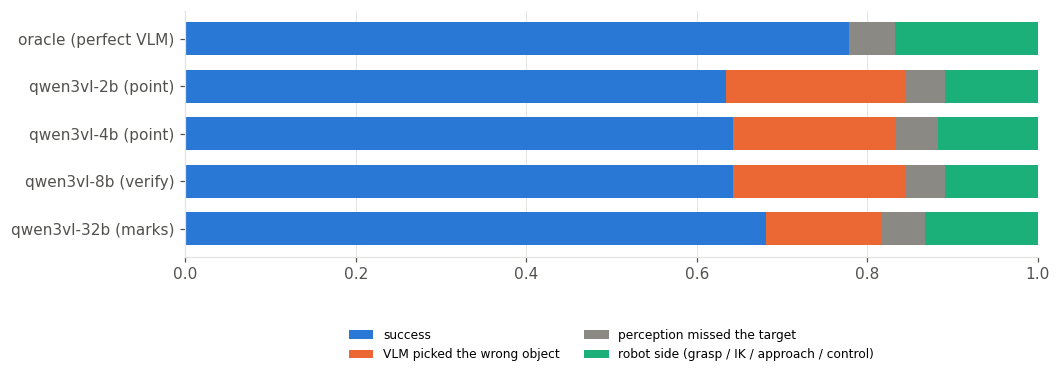

| Grounding | Success | failed: VLM | failed: perception | failed: robot side |
|---|---|---|---|---|
| qwen3vl-32b (marks) | 68.1% [62–73] (n=257) | 14% | 5% | 13% |
| qwen3vl-8b (verify) | 64.2% [58–70] (n=257) | 20% | 5% | 11% |
| qwen3vl-4b (point) | 64.2% [58–70] (n=257) | 19% | 5% | 12% |
| qwen3vl-2b (point) | 63.4% [57–69] (n=257) | 21% | 5% | 11% |
| oracle (perfect VLM) | 77.8% [72–82] (n=257) | 0% | 5% | 17% |


In [8]:
E3 = [('oracle (perfect VLM)', 'e1_b_refine')] + [(f'{m} ({BEST.get(m, "?")})', f'e3_{m}') for m in ['qwen3vl-2b', 'qwen3vl-4b', 'qwen3vl-8b', 'qwen3vl-32b']]
GROUP = {'grounding': 'VLM picked the wrong object', 'segmentation': 'perception missed the target'}
rows = []
fig, ax = plt.subplots(figsize=(10, 2.9))
for i, (lab, run) in enumerate(E3[::-1]):
    R = load(run)
    if not R: ax.text(0.01, i, 'pending', va='center', fontsize=8, color=INK2); continue
    c = collections.Counter('success' if x.get('success') else GROUP.get(x['fail'], 'robot side (grasp / IK / approach / control)') for x in R)
    left = 0
    for k, col in [('success', '#2a78d6'), ('VLM picked the wrong object', '#eb6834'), ('perception missed the target', '#8a8984'), ('robot side (grasp / IK / approach / control)', '#1baf7a')]:
        v = c.get(k, 0) / len(R); ax.barh(i, v, left=left, color=col, height=0.7, label=k if i == len(E3) - 1 else None); left += v
    rows.append([lab, fmt(R), f"{100*c.get('VLM picked the wrong object', 0)/len(R):.0f}%", f"{100*c.get('perception missed the target', 0)/len(R):.0f}%",
                 f"{100*c.get('robot side (grasp / IK / approach / control)', 0)/len(R):.0f}%"])
ax.set_yticks(range(len(E3))); ax.set_yticklabels([l for l, _ in E3[::-1]]); ax.set_xlim(0, 1); ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2, fontsize=8); plt.show()
table(rows, ['Grounding', 'Success', 'failed: VLM', 'failed: perception', 'failed: robot side'])

**Reading sections 3 and 4.**
* **Grounding barely improves from 2B to 8B; 32B is the first clear step.** In each model's best mode on the 257 eval scenes:

  | Model | Best eval accuracy (mode) |
  |---|---|
  | 2B | 73% (verify) |
  | 4B | 75% (verify) |
  | 8B | 73% (marks / verify) |
  | 32B | 79% (marks) |

  Given that the target was segmented at all, 32B marks reaches 86%, against about 80% for the smaller models.
* **The modes don't scale the same way.**
  * Pointing does not improve with size. The 8B model often refuses ("There are none.", "There is no bleach bottle in the image", 44 + 11 cases), and the 32B model refuses on the clamp and the bleach bottle.
  * Set-of-marks gains the most from size (65% → 75% → 73% → 79%). It is also the fastest mode, with a one-token answer (0.2 s even for 32B).
  * Verify (crop + Yes/No logit) is the most stable across sizes, but it needs one forward pass per proposal.
* **The remaining confusions are between look-alikes:** gelatin vs pudding vs sugar box (three small boxes), potted-meat vs tomato-soup vs coffee can, and foam brick vs wooden block. They come from a 640×480 view at about 1.1 m, where these objects are 30–60 px across. A higher-resolution external camera, or asking the VLM on the wrist view after the look move, are the obvious next tries.
* **Who fails?** Once the VLM is right, the rest of the pipeline succeeds 84–85% of the time for every model, the same as with the oracle (82%). So the robot side is not the bottleneck for VLM-grounded runs:
  * The wrong-object rate (2B 21%, 4B 19%, 8B 20%, 32B 14%) accounts for nearly the whole gap between each model and the oracle.
  * Robot-side failures stay at about 11–13% of episodes for every model, mostly `grasp_plan` on the cracker box and scissors.
  * Perception misses stay at about 5%.
* The dev-chosen mode is not always the best on eval (4B: point chosen on dev, verify slightly better on eval). With 43 dev scenes, differences of a few points between modes are within noise (see the CIs).

---
## 5. Videos

External camera, 20 fps. The first 6 evaluation episodes of each config, chosen by rule (episode order), not by outcome.

In [9]:
for name in ['e1_a_extonly', 'e1_b_refine', 'e1_e_native']:
    for v in sorted(glob.glob(f'{ROOT}/demo/franka/{name}/*.mp4'))[:3]:
        show(v, w=480, caption=f'**{name}**: `{os.path.basename(v)}`')

**e1_a_extonly**: `100_004_sugar_box_ok.mp4`

**e1_a_extonly**: `100_011_banana_ok.mp4`

**e1_a_extonly**: `100_021_bleach_cleanser_fail.mp4`

**e1_b_refine**: `100_004_sugar_box_ok.mp4`

**e1_b_refine**: `100_011_banana_ok.mp4`

**e1_b_refine**: `100_021_bleach_cleanser_ok.mp4`

**e1_e_native**: `100_004_sugar_box_fail.mp4`

**e1_e_native**: `100_011_banana_ok.mp4`

**e1_e_native**: `100_021_bleach_cleanser_fail.mp4`

---
## 6. Moving to the real Franka

What is already shared:
* the episode loop, perception, VLM grounding, grasp planner and IK (`vrg/franka/*`);
* `real_franky.py`, which implements the same interface with franky and two RealSense cameras.

Before the first real run:
1. **Calibrate.** External camera → base (a ChArUco board held by the robot, or `easy_handeye2`), and wrist camera → TCP (hand-eye). Both go in `calib.json`. The sim's camera poses are the defaults to mimic.
2. **Desk end effector** = Franka Hand, so franky's `O_T_EE` is the TCP used here (0.1034 m, −45°).
3. **Dry run** (`dry_run=True`): perception + VLM + grasp planning on live images, motions disabled, and check the planned grasps overlaid on the image.
4. **Slow first motions**: `relative_dynamics_factor = 0.05`, workspace bounds in `perception.Workspace` set to the real table.
5. **Depth noise**: RealSense depth is noisier than the simulator's at object edges. The look-then-grasp wrist view (≈ 30 cm range) is the main defence, and D405-class close-range cameras are a good fit for the wrist.

Sim-to-real gaps to expect: depth noise and missing depth on shiny or transparent surfaces, camera calibration error (a few mm to 1 cm), contact physics of the soft fingertips, and object weights.

---
## 7. Summary

| Question | Answer (257 eval episodes, 13 YCB targets, 6 objects per scene) |
|---|---|
| How good is the scripted grasp with a perfect VLM? | **78%** with a wrist look-then-grasp (49% from the external camera alone). |
| Better controller? | Our planned IK (goal IK with limits, null-space posture and restarts, then min-jerk joints plus straight-line approach and lift) converges where Isaac's one-step differential IK stalls or swings into the object: **78% vs 56%** (both are about 3 mm accurate when they converge). Pure joint moves are on par in sim (77%). |
| Does a bigger VLM help? | Little from 2B to 8B (73–75% grounding, 63–64% end to end); **32B: 79% grounding, 68% end to end**. Set-of-marks scales best and is fastest. |
| Is the VLM or the grasp failing? | **The VLM**, with grounding errors 14–21% of episodes. Given correct grounding, the robot side succeeds about 85% for every model. Robot-side failures (11–13%) are mostly top-down grasps of objects wider than the hand. |

**Next steps:**
* Robot side: side or edge grasps for wide or flat objects (the cracker box), and better segmentation of thin objects (the scissors).
* VLM side: ground on the wrist view or a higher-resolution external image, and fall back from pointing to marks when the model refuses.
* Real arm: the checklist in section 6. The episode code runs unchanged on `FrankyRobot`.